# Mini-Project 2 — Uganda Tax Engine

**Goal.** An extensible, testable tax calculator that models Uganda Revenue Authority (URA) rules: PAYE, NSSF, Local Service Tax, VAT and corporate income tax, plus a tax planner (Extension B).

All reusable code is in `src/tax/`; this notebook demonstrates it, checks results by hand, and answers the discussion questions.

## Tax rates and the version used

The brief says: *"Confirm the tax rates against the URA documentation and cite the version you used."* Rates were checked on **7 October 2026**.

| Tax | Rule implemented | Source and version |
|---|---|---|
| PAYE, resident, **from 1 Jul 2026** | Nil to 335,000; 20 % to 410,000; 25 % to 485,000; 30 % above; +10 % of the excess over 10,000,000 (monthly) | Income Tax (Amendment) Act, 2026 (assented 20 Aug 2026, effective 1 Jul 2026), as given in the assignment brief and summarised in the [KAA tax alert](https://www.kaa.co.ug/kaa-tax-alert-income-tax-amendment-act-2026/) |
| PAYE, resident, 1 Jul 2012 – 30 Jun 2026 | Nil to 235,000; 10 % to 335,000; 20 % to 410,000; 30 % above; +10 % over 10,000,000 | [URA PAYE rates page](https://ura.go.ug/en/domestic-taxes/paye-rates/) |
| PAYE, non-resident | 10 % to 335,000; 20 % to 410,000; 30 % above; +10 % over 10,000,000 | [URA PAYE rates page](https://ura.go.ug/en/domestic-taxes/paye-rates/) |
| NSSF | Employee 5 % of gross, employer 10 % | NSSF Act (as in the brief) |
| Local Service Tax | Annual amount by monthly-income bracket (5,000 to 100,000), four instalments July–October, deducted before PAYE | Local Governments (Amendment) (No. 2) Act 2008; [KCCA LST FAQs](https://www.kcca.go.ug/uDocs/Local_Service_Tax_FAQs.pdf) |
| VAT | 18 % standard; zero-rated; exempt; input tax apportioned with 5 % / 95 % rule | [PwC Tax Summaries: Uganda, other taxes](https://taxsummaries.pwc.com/uganda/corporate/other-taxes) (reviewed 12 Jan 2026) |
| Corporate income tax | 30 % of chargeable income (resident companies) | [PwC Tax Summaries: Uganda, corporate income](https://taxsummaries.pwc.com/uganda/corporate/taxes-on-corporate-income) |
| Dividend withholding tax (extension) | 15 % for resident individuals, a final tax | [PwC Tax Summaries: Uganda, withholding taxes](https://taxsummaries.pwc.com/uganda/corporate/withholding-taxes) |

**A finding from the confirmation step.** On the date checked, URA's own PAYE rates page still showed the **pre-July-2026** resident bands (235,000 threshold). The brief's baseline matches the **2026 amendment**. The engine holds **both** as dated schedules and picks the right one from the pay date, so neither had to be thrown away. This is why `NoScheduleForDateError` exists.

**Assumptions**
- All employment figures are **monthly**; corporate figures are **annual**. Amounts are in whole Uganda shillings.
- Allowances are taxable employment income. NSSF is **not** deductible for PAYE.
- Invoice amounts are **VAT-exclusive**.
- The non-resident schedule is treated as unchanged by the 2026 Act (no source reported a change).

In [1]:
import datetime as dt
import subprocess
import sys
from decimal import Decimal

import matplotlib.pyplot as plt
import pandas as pd

from src.tax import (
    PAYE, NSSF, LocalServiceTax, PayrollPipeline, VAT, CorporateIncomeTax, WithholdingTax,
    Money, TaxContext, Residency, Invoice, InvoiceKind, SupplyType, Tax,
    TaxError, InvalidIncomeError, NoScheduleForDateError, InvalidInvoiceError, MoneyTypeError,
    TaxPlanner, SalaryScenario, DividendScenario, default_registry,
)

PAY_DATE = dt.date(2026, 9, 15)        # after 1 July 2026 -> the new schedule; September is an LST month
OLD_DATE = dt.date(2026, 3, 15)        # before 1 July 2026 -> the old schedule

def ugx(m: Money) -> int:
    "Money -> int, for tables and charts only (never for calculation)."
    return int(m.amount)

pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Design at a glance

```
TaxContext (facts) ──► Tax.calculate(ctx) ──► TaxResult (amount, base, breakdown, basis)

Tax (abstract base class)
 ├── PAYE ───────────── uses ──► ScheduleRegistry ──► ProgressiveSchedule ──► Band
 ├── NSSF
 ├── LocalServiceTax
 ├── VAT ────────────── reads ─► Invoice (SupplyType, InvoiceKind)
 ├── CorporateIncomeTax
 └── WithholdingTax

PayrollPipeline ── has ──► LocalServiceTax, PAYE, NSSF ──► Payslip
TaxPlanner ── compares ──► Scenario (abstract) ◄── SalaryScenario, DividendScenario
Money: value object used by everything      TaxError ◄── InvalidIncomeError, NoScheduleForDateError, …
```

| Mandatory constraint | Where it is met |
|---|---|
| Abstract `Tax` with `calculate(self, ctx: TaxContext) -> TaxResult` | `src/tax/core.py` |
| `Decimal` only; `Money` value object with rounding rule and `__add__`, `__mul__`, `__lt__`, `__repr__` | `src/tax/money.py` |
| Exception hierarchy `TaxError`, `InvalidIncomeError`, `NoScheduleForDateError` | `src/tax/errors.py` |
| Boundary tests at every band edge; property-based tests with hypothesis | `tests/test_paye_boundaries.py`, `tests/test_tax_properties.py` |

In [2]:
# Every tax is a Tax, and Tax itself cannot be instantiated (it is abstract).
for tax in (PAYE(), NSSF(), LocalServiceTax(), VAT(), CorporateIncomeTax(), WithholdingTax()):
    print(f"{type(tax).__name__:20s} is a Tax: {isinstance(tax, Tax)}")
try:
    Tax()
except TypeError as err:
    print("\nTax() ->", err)

PAYE                 is a Tax: True
NSSF                 is a Tax: True
LocalServiceTax      is a Tax: True
VAT                  is a Tax: True
CorporateIncomeTax   is a Tax: True
WithholdingTax       is a Tax: True

Tax() -> Can't instantiate abstract class Tax with abstract method calculate


## 2. `Money`: exact shillings

`Money` wraps a `Decimal`, is immutable, and has one rounding rule: **round half up to the nearest whole shilling**. Multi-step calculations (like progressive tax) are done on exact Decimals and rounded **once** at the end.

In [3]:
a, b = Money(1_000_000), Money("250000")
print("a + b            =", a + b)                       # __add__
print("a - b            =", a - b)
print("a * 18%          =", a * Decimal("0.18"))          # __mul__ with a Decimal rate
print("a < b            =", a < b, "| max:", max(a, b))    # __lt__ (and the other comparisons)
print("repr             =", repr(a))                       # __repr__
print("sum of a list    =", sum([a, b, Money(1)]))
print("half-up rounding =", Money("184.5"), "and", Money("184.4"))
print("usable as dict key / in a set:", len({Money(5), Money(5), Money(6)}), "distinct values")

a + b            = UGX 1,250,000
a - b            = UGX 750,000
a * 18%          = UGX 180,000
a < b            = False | max: UGX 1,000,000
repr             = Money('UGX 1,000,000')
sum of a list    = UGX 1,250,001
half-up rounding = UGX 185 and UGX 184
usable as dict key / in a set: 2 distinct values


In [4]:
# float is refused at every door, with a message that says what to do instead
for label, action in {
    "Money(0.1)":          lambda: Money(0.1),
    "Money(1000) * 0.18":  lambda: Money(1000) * 0.18,
    "Money(10) * Money(10)": lambda: Money(10) * Money(10),
    "Money('abc')":        lambda: Money("abc"),
}.items():
    try:
        action()
    except MoneyTypeError as err:
        print(f"{label:24s} -> MoneyTypeError: {err}")

Money(0.1)               -> MoneyTypeError: Money does not accept float (0.1). Use int, str or decimal.Decimal, e.g. Money('1500.50').
Money(1000) * 0.18       -> MoneyTypeError: Multiply Money by int or Decimal, never float.
Money(10) * Money(10)    -> MoneyTypeError: Cannot multiply Money by Money.
Money('abc')             -> MoneyTypeError: 'abc' is not a valid amount.


## 3. Functional requirement 1 — PAYE calculator

Inputs: monthly gross pay, allowances, residency status (and the pay date, which selects the schedule).

In [5]:
paye = PAYE()
ctx = TaxContext(on_date=PAY_DATE, residency=Residency.RESIDENT,
                 gross_pay=Money(11_000_000), allowances=Money(1_000_000))
print(paye.calculate(ctx).explain())

PAYE: UGX 3,688,250  (on a base of UGX 12,000,000)
    0% of 335,000 (band 0 to 335,000)                                 UGX 0
    20% of 75,000 (band 335,000 to 410,000)                      UGX 15,000
    25% of 75,000 (band 410,000 to 485,000)                      UGX 18,750
    30% of 11,515,000 (band 485,000 and above)                UGX 3,454,500
    plus 10% of 2,000,000 over 10,000,000                       UGX 200,000
    basis: Resident individuals, monthly (from 1 Jul 2026). Income Tax (Amendment) Act, 2026 (assented 20 Aug 2026, effective 1 Jul 2026); assignment baseline


**Hand check** for chargeable income 12,000,000 (resident, new schedule):

$$\underbrace{0.20\times75{,}000}_{15{,}000}+\underbrace{0.25\times75{,}000}_{18{,}750}+\underbrace{0.30\times11{,}515{,}000}_{3{,}454{,}500}+\underbrace{0.10\times2{,}000{,}000}_{200{,}000}=3{,}688{,}250$$

The brief's formula gives the same: $33{,}750 + 30\%\times(12{,}000{,}000-485{,}000) + 10\%\times(12{,}000{,}000-10{,}000{,}000) = 3{,}688{,}250$. ✓

In [6]:
def paye_for(gross: int, residency=Residency.RESIDENT, on=PAY_DATE) -> int:
    return ugx(paye.calculate(TaxContext(on_date=on, residency=residency, gross_pay=Money(gross))).amount)

edges = [0, 235_000, 335_000, 335_001, 335_100, 410_000, 410_100, 485_000, 485_100,
         1_000_000, 3_000_000, 10_000_000, 10_000_001, 10_000_100, 15_000_000]
band_table = pd.DataFrame({
    "Monthly income": edges,
    "Resident (from Jul 2026)": [paye_for(g) for g in edges],
    "Resident (before Jul 2026)": [paye_for(g, on=OLD_DATE) for g in edges],
    "Non-resident": [paye_for(g, Residency.NON_RESIDENT) for g in edges],
}).set_index("Monthly income")
band_table.style.format("{:,.0f}")

,Resident (from Jul 2026),Resident (before Jul 2026),Non-resident
Monthly income,,,
0,0,0,0
235000,0,0,"23,500"
335000,0,"10,000","33,500"
335001,0,"10,000","33,500"
335100,20,"10,020","33,520"
410000,"15,000","25,000","48,500"
410100,"15,025","25,030","48,530"
485000,"33,750","47,500","71,000"
485100,"33,780","47,530","71,030"


Reading the edges (resident, from July 2026): 335,000 → 0; 410,000 → 15,000; 485,000 → 33,750; 10,000,000 → 2,888,250, exactly the fixed amounts in the brief. One shilling above an edge (335,001; 10,000,001) adds less than half a shilling of tax, which rounds to 0. So the table also shows 100 shillings above each edge, where the band's rate is visible (20, 25, 30 and 40 shillings per extra 100).

Non-residents have **no tax-free threshold**: 10 % applies from the first shilling.

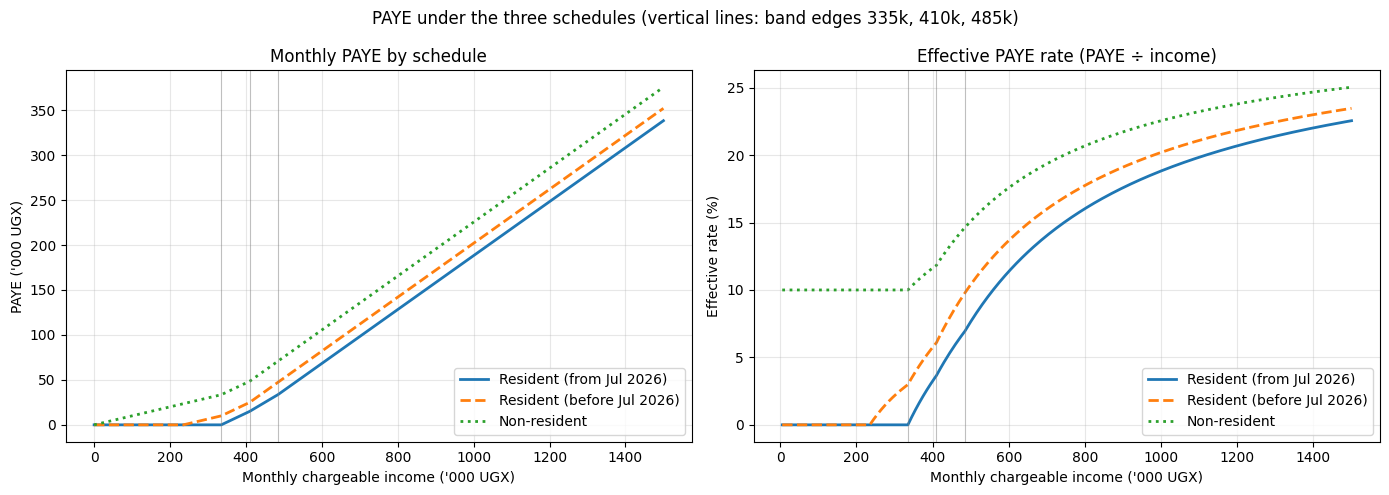

In [7]:
incomes = list(range(0, 1_500_001, 5_000))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
series = {
    "Resident (from Jul 2026)": dict(residency=Residency.RESIDENT, on=PAY_DATE),
    "Resident (before Jul 2026)": dict(residency=Residency.RESIDENT, on=OLD_DATE),
    "Non-resident": dict(residency=Residency.NON_RESIDENT, on=PAY_DATE),
}
styles = {"Resident (from Jul 2026)": "-", "Resident (before Jul 2026)": "--", "Non-resident": ":"}
for label, kw in series.items():
    taxes = [paye_for(g, **kw) for g in incomes]
    axes[0].plot([g / 1000 for g in incomes], [t / 1000 for t in taxes], styles[label], lw=2, label=label)
    axes[1].plot([g / 1000 for g in incomes[1:]], [100 * t / g for g, t in zip(incomes[1:], taxes[1:])],
                 styles[label], lw=2, label=label)
for edge in (335, 410, 485):
    for ax in axes:
        ax.axvline(edge, color="grey", lw=0.8, alpha=0.5)
axes[0].set(title="Monthly PAYE by schedule", xlabel="Monthly chargeable income ('000 UGX)", ylabel="PAYE ('000 UGX)")
axes[1].set(title="Effective PAYE rate (PAYE ÷ income)", xlabel="Monthly chargeable income ('000 UGX)", ylabel="Effective rate (%)")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
fig.suptitle("PAYE under the three schedules (vertical lines: band edges 335k, 410k, 485k)")
fig.tight_layout(); fig.savefig("figures/tax_paye_schedules.png", dpi=150); plt.show()

In [8]:
# The schedule is chosen by date. A date nobody has a schedule for is an error, not a guess.
for on in (dt.date(2026, 6, 30), dt.date(2026, 7, 1), dt.date(2010, 1, 1)):
    try:
        r = paye.calculate(TaxContext(on_date=on, gross_pay=Money(300_000)))
        print(f"{on}: PAYE on 300,000 = {r.amount}   [{r.basis.split('.')[0]}]")
    except NoScheduleForDateError as err:
        print(f"{on}: NoScheduleForDateError -> {err}")

2026-06-30: PAYE on 300,000 = UGX 6,500   [Resident individuals, monthly (1 Jul 2012 - 30 Jun 2026)]
2026-07-01: PAYE on 300,000 = UGX 0   [Resident individuals, monthly (from 1 Jul 2026)]
2010-01-01: NoScheduleForDateError -> No resident PAYE schedule is in force on 2010-01-01. Known periods: 2012-07-01 to 2026-06-30, 2026-07-01 to now.


The 2026 amendment made a 300,000-shilling earner tax-free overnight (6,500 → 0). The saving for every resident earning above 485,000 a month is a flat **13,750 shillings** (e.g. 3,000,000: 802,000 → 788,250), because only the lower bands changed.

## 4. Functional requirement 2 — Payroll pipeline

### Order of deductions, and why

| Step | Calculation | Why in this position |
|---|---|---|
| 1 | **Gross** = basic pay + taxable allowances | Everything else is a percentage or function of gross. |
| 2 | **Local Service Tax** instalment (if enabled, July–October) | LST is allowed as a deduction when computing chargeable employment income, so it must be known **before** PAYE. The brief also says "applied before PAYE". |
| 3 | **Chargeable income** = gross − LST | The PAYE base. |
| 4 | **PAYE** on chargeable income | Depends on step 3. |
| 5 | **NSSF** = 5 % of **gross** | NSSF is **not** deductible for PAYE in Uganda, so it does not reduce chargeable income and is computed on gross. Its position relative to PAYE does not change any number; we list it after PAYE because it is a deduction from pay, not from taxable income. |
| 6 | **Net pay** = gross − LST − PAYE − NSSF | |
| – | Employer NSSF = 10 % of gross | A cost to the employer **on top of** gross; never deducted from the employee. |

The key ordering decision is LST → PAYE: swapping them would overstate PAYE by the band rate × the LST instalment.

In [9]:
payroll = PayrollPipeline()
slip = payroll.run(Money(2_500_000), PAY_DATE, allowances=Money(500_000), residency=Residency.RESIDENT)
pd.DataFrame(slip.as_rows(), columns=["Line", "UGX"]).assign(UGX=lambda d: d["UGX"].map(ugx)).style.format({"UGX": "{:,.0f}"}).hide(axis="index")

Line,UGX
Gross pay (basic + allowances),"3,000,000"
1. Local Service Tax,"25,000"
Chargeable income (gross - LST),"2,975,000"
2. PAYE,"780,750"
3. NSSF employee 5% (on gross),"150,000"
Total deductions,"955,750"
NET PAY,"2,044,250"
Employer NSSF 10% (extra cost),"300,000"
Total cost to employer,"3,300,000"


**Hand check** (gross 3,000,000 in September): income is above 1,000,000, so annual LST is 100,000 and the instalment is 100,000 ÷ 4 = **25,000**. Chargeable = 2,975,000. PAYE = 33,750 + 30 % × (2,975,000 − 485,000) = 33,750 + 747,000 = **780,750**. NSSF = 5 % × 3,000,000 = **150,000**. Net = 3,000,000 − 25,000 − 780,750 − 150,000 = **2,044,250**. ✓

In [10]:
# Local Service Tax is configurable: on/off, number of instalments, which months
variants = {
    "Default (4 instalments, Jul-Oct), September": (PayrollPipeline(), PAY_DATE),
    "Default, January (no instalment due)":        (PayrollPipeline(), dt.date(2027, 1, 15)),
    "LST disabled":                                (PayrollPipeline(lst=LocalServiceTax(enabled=False)), PAY_DATE),
    "LST in one lump sum in July":                 (PayrollPipeline(lst=LocalServiceTax(instalments=1, months=(7,))), dt.date(2026, 7, 15)),
    "Non-resident, September":                     (PayrollPipeline(), PAY_DATE),
}
rows = []
for label, (pipeline, on) in variants.items():
    res = Residency.NON_RESIDENT if label.startswith("Non-resident") else Residency.RESIDENT
    s = pipeline.run(Money(3_000_000), on, residency=res)
    rows.append({"Configuration": label, "LST": ugx(s.lst.amount), "PAYE": ugx(s.paye.amount),
                 "NSSF": ugx(s.nssf.amount), "Net pay": ugx(s.net_pay)})
pd.DataFrame(rows).set_index("Configuration").style.format("{:,.0f}")

,LST,PAYE,NSSF,Net pay
Configuration,,,,
"Default (4 instalments, Jul-Oct), September","25,000","780,750","150,000","2,044,250"
"Default, January (no instalment due)",0,"788,250","150,000","2,061,750"
LST disabled,0,"788,250","150,000","2,061,750"
LST in one lump sum in July,"100,000","758,250","150,000","1,991,750"
"Non-resident, September","25,000","818,000","150,000","2,007,000"


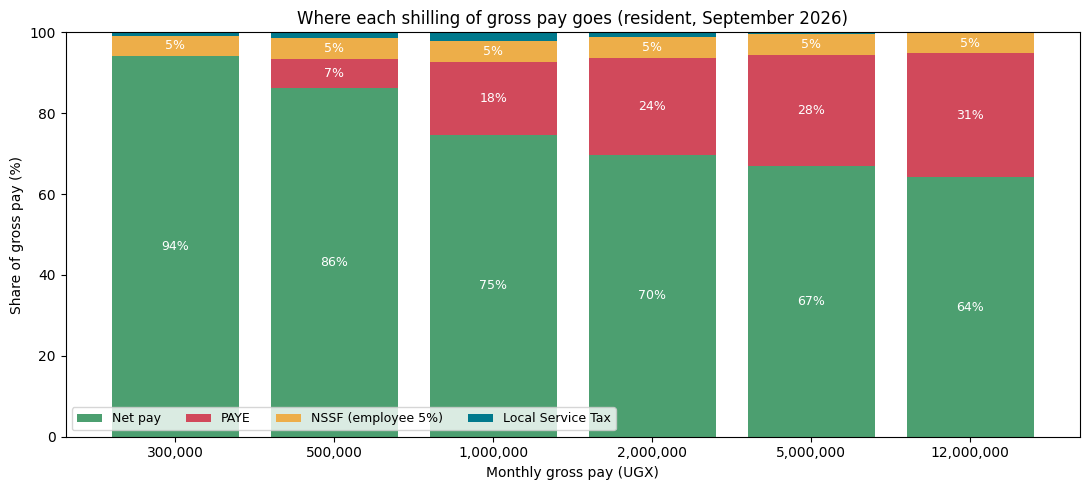

In [11]:
salaries = [300_000, 500_000, 1_000_000, 2_000_000, 5_000_000, 12_000_000]
slips = [payroll.run(Money(s), PAY_DATE) for s in salaries]
parts = {
    "Net pay": [ugx(s.net_pay) for s in slips],
    "PAYE": [ugx(s.paye.amount) for s in slips],
    "NSSF (employee 5%)": [ugx(s.nssf.amount) for s in slips],
    "Local Service Tax": [ugx(s.lst.amount) for s in slips],
}
fig, ax = plt.subplots(figsize=(11, 5))
bottom = [0.0] * len(salaries)
colours = {"Net pay": "#4c9f70", "PAYE": "#d1495b", "NSSF (employee 5%)": "#edae49", "Local Service Tax": "#00798c"}
labels = [f"{s:,}" for s in salaries]
for name, values in parts.items():
    share = [100 * v / s for v, s in zip(values, salaries)]
    bars = ax.bar(labels, share, bottom=bottom, label=name, color=colours[name])
    for rect, pct in zip(bars, share):
        if pct >= 4:
            ax.text(rect.get_x() + rect.get_width() / 2, rect.get_y() + rect.get_height() / 2, f"{pct:.0f}%",
                    ha="center", va="center", color="white", fontsize=9)
    bottom = [b + s for b, s in zip(bottom, share)]
ax.set(title="Where each shilling of gross pay goes (resident, September 2026)",
       xlabel="Monthly gross pay (UGX)", ylabel="Share of gross pay (%)", ylim=(0, 100))
ax.legend(loc="lower left", ncol=4, fontsize=9)
fig.tight_layout(); fig.savefig("figures/tax_payslip_shares.png", dpi=150); plt.show()

In [12]:
# An oddity worth knowing: the LST "cliff". One extra shilling of pay can REDUCE net pay in an LST month.
for gross in (600_000, 600_001):
    s = payroll.run(Money(gross), PAY_DATE)
    print(f"gross {gross:>9,}: LST {ugx(s.lst.amount):>6,}  PAYE {ugx(s.paye.amount):>7,}  NSSF {ugx(s.nssf.amount):>6,}  net {ugx(s.net_pay):>9,}")

gross   600,000: LST 10,000  PAYE  65,250  NSSF 30,000  net   494,750
gross   600,001: LST 15,000  PAYE  63,750  NSSF 30,000  net   491,251


Crossing the 600,000 LST bracket raises the annual LST from 40,000 to 60,000 (instalment 10,000 → 15,000), so a one-shilling raise costs about 3,500 shillings of net pay in that month. LST is a *step* tax, not a marginal one. The property-based tests found this: "net pay never falls when gross rises" only holds with LST switched off, so the test is written that way and the behaviour is documented here rather than hidden.

## 5. Functional requirement 3 — VAT module

- **Standard-rated**: 18 % VAT charged; input VAT on costs is claimable.
- **Zero-rated** (e.g. exports): taxable at 0 %, and input VAT is **still claimable**, so exporters are often in a refund position.
- **Exempt** (e.g. financial or medical services): no VAT charged and related input VAT is **not** claimable.

When a business makes both taxable and exempt sales, input VAT is apportioned: claimable share = taxable sales ÷ total sales (all of it if exempt sales are under 5 % of the total; none if over 95 %).

In [13]:
invoices = (
    Invoice("S-001", InvoiceKind.SALE, SupplyType.STANDARD,   Money(10_000_000), "Furniture sold in Kampala"),
    Invoice("S-002", InvoiceKind.SALE, SupplyType.ZERO_RATED, Money(4_000_000),  "Furniture exported to Kenya"),
    Invoice("S-003", InvoiceKind.SALE, SupplyType.EXEMPT,     Money(6_000_000),  "Exempt supply"),
    Invoice("P-001", InvoiceKind.PURCHASE, SupplyType.STANDARD, Money(5_000_000), "Timber and fittings"),
    Invoice("P-002", InvoiceKind.PURCHASE, SupplyType.EXEMPT,   Money(1_000_000), "Exempt purchase (no VAT on it)"),
)
vat = VAT()
inv_df = pd.DataFrame([{"No.": i.number, "Kind": i.kind.value, "Supply": i.supply_type.value,
                        "Net amount": ugx(i.net_amount), "VAT @18%": ugx(i.vat(vat.rate)), "Description": i.description}
                       for i in invoices])
display(inv_df.style.format({"Net amount": "{:,.0f}", "VAT @18%": "{:,.0f}"}).hide(axis="index"))
result = vat.calculate(TaxContext(on_date=PAY_DATE, invoices=invoices))
print(result.explain())
print(f"\nNet VAT payable = {result.amount}")

No.,Kind,Supply,Net amount,VAT @18%,Description
S-001,sale,standard-rated,"10,000,000","1,800,000",Furniture sold in Kampala
S-002,sale,zero-rated,"4,000,000",0,Furniture exported to Kenya
S-003,sale,exempt,"6,000,000",0,Exempt supply
P-001,purchase,standard-rated,"5,000,000","900,000",Timber and fittings
P-002,purchase,exempt,"1,000,000",0,Exempt purchase (no VAT on it)


VAT: UGX 1,170,000  (on a base of UGX 14,000,000)
    Output VAT: 18% of standard-rated sales 10,000,000        UGX 1,800,000
    Zero-rated sales 4,000,000 at 0%                                  UGX 0
    Exempt sales 6,000,000 (no VAT)                                   UGX 0
    Input VAT on standard-rated purchases                       UGX 900,000
    Claimable input VAT (70.00% recoverable)                    UGX 630,000
    basis: VAT Act: standard rate 18%; input tax apportioned where exempt supplies are made

Net VAT payable = UGX 1,170,000


**Hand check.** Output VAT = 18 % × 10,000,000 = 1,800,000. Input VAT = 18 % × 5,000,000 = 900,000. Taxable sales are 14,000,000 of 20,000,000 = 70 %, so claimable input VAT = 630,000. Net payable = 1,800,000 − 630,000 = **1,170,000**. ✓

In [14]:
def scenario(label, *invs):
    s = vat.summarise(invs)
    return {"Scenario": label, "Output VAT": ugx(s.output_vat), "Input VAT": ugx(s.input_vat),
            "Recoverable": f"{s.recoverable_fraction:.0%}", "Net VAT payable": ugx(s.net_vat_payable)}

purchase = Invoice("P", InvoiceKind.PURCHASE, SupplyType.STANDARD, Money(4_000_000))
pd.DataFrame([
    scenario("All sales standard-rated", Invoice("S", InvoiceKind.SALE, SupplyType.STANDARD, Money(10_000_000)), purchase),
    scenario("All sales zero-rated (exporter)", Invoice("S", InvoiceKind.SALE, SupplyType.ZERO_RATED, Money(10_000_000)), purchase),
    scenario("All sales exempt", Invoice("S", InvoiceKind.SALE, SupplyType.EXEMPT, Money(10_000_000)), purchase),
]).set_index("Scenario").style.format({"Output VAT": "{:,.0f}", "Input VAT": "{:,.0f}", "Net VAT payable": "{:,.0f}"})

,Output VAT,Input VAT,Recoverable,Net VAT payable
Scenario,,,,
All sales standard-rated,"1,800,000","720,000",100%,"1,080,000"
All sales zero-rated (exporter),0,"720,000",100%,"-720,000"
All sales exempt,0,"720,000",0%,0


The same purchases give three different outcomes: pay 1,080,000 (standard), a **refund** of 720,000 (zero-rated), or nothing either way (exempt). This is the practical difference between "zero-rated" and "exempt", which both look like "no VAT" to the customer.

## 6. Functional requirement 4 — Corporate income tax

Chargeable income = revenue − allowable deductions; tax = 30 % of it. A loss gives zero tax (not negative tax).

In [15]:
cit = CorporateIncomeTax()
profit_case = TaxContext(on_date=PAY_DATE, revenue=Money(500_000_000), allowable_deductions=Money(380_000_000))
loss_case = TaxContext(on_date=PAY_DATE, revenue=Money(200_000_000), allowable_deductions=Money(260_000_000))
print(cit.calculate(profit_case).explain())
print()
print(cit.calculate(loss_case).explain())

Corporate income tax: UGX 36,000,000  (on a base of UGX 120,000,000)
    Chargeable income: 500,000,000 - 380,000,000            UGX 120,000,000
    30% of 120,000,000                                       UGX 36,000,000
    basis: Income Tax Act: 30% of chargeable income for resident companies

Corporate income tax: UGX 0  (on a base of UGX 0)
    Revenue 200,000,000 - deductions 260,000,000            UGX -60,000,000
    Tax loss carried forward: no tax this year                        UGX 0
    basis: Income Tax Act: 30% of chargeable income for resident companies


**Hand check.** 500,000,000 − 380,000,000 = 120,000,000; 30 % × 120,000,000 = **36,000,000**. ✓

## 7. Validation and errors: never fail silently

Every error the engine raises is a `TaxError`, so callers can catch them all together or one by one.

In [16]:
bad_inputs = {
    "negative income":            lambda: TaxContext(on_date=PAY_DATE, gross_pay=Money(-1)),
    "income not wrapped in Money": lambda: TaxContext(on_date=PAY_DATE, gross_pay=1_000_000),
    "PAYE with no income given":  lambda: PAYE().calculate(TaxContext(on_date=PAY_DATE)),
    "date with no schedule":      lambda: PAYE().calculate(TaxContext(on_date=dt.date(2009, 1, 1), gross_pay=Money(1))),
    "negative invoice":           lambda: Invoice("X", InvoiceKind.SALE, SupplyType.STANDARD, Money(-5)),
    "corporate tax, no revenue":  lambda: CorporateIncomeTax().calculate(TaxContext(on_date=PAY_DATE)),
    "float money":                lambda: Money(1500.50),
}
for label, action in bad_inputs.items():
    try:
        action()
        print(f"{label:30s} -> no error (BUG!)")
    except TaxError as err:
        print(f"{label:30s} -> {type(err).__name__}: {err}")

negative income                -> InvalidIncomeError: gross_pay cannot be negative (UGX -1).
income not wrapped in Money    -> InvalidIncomeError: gross_pay must be Money, got int. Wrap it: Money(1000000).
PAYE with no income given      -> InvalidIncomeError: This tax needs 'gross_pay', but it was not provided.
date with no schedule          -> NoScheduleForDateError: No resident PAYE schedule is in force on 2009-01-01. Known periods: 2012-07-01 to 2026-06-30, 2026-07-01 to now.
negative invoice               -> InvalidInvoiceError: Invoice X: amount cannot be negative.
corporate tax, no revenue      -> InvalidIncomeError: This tax needs 'revenue', but it was not provided.
float money                    -> MoneyTypeError: Money does not accept float (1500.5). Use int, str or decimal.Decimal, e.g. Money('1500.50').


## 8. Testing

- **Boundary tests** (`tests/test_paye_boundaries.py`): every band edge in the brief (335,000; 335,001; 410,000; 485,000; 10,000,000; 10,000,001), 100 shillings inside each band, the non-resident and pre-2026 schedules, and the switch date.
- **Property-based tests** (`tests/test_tax_properties.py`): hypothesis generates hundreds of random incomes, residencies and dates and checks that tax is **never negative**, **never exceeds income**, and is **monotonic** in income.
- Unit tests for `Money`, payroll, LST, VAT, corporate tax and the planner.

In [17]:
run = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider",
                      "tests/test_money.py", "tests/test_paye_boundaries.py", "tests/test_tax_properties.py",
                      "tests/test_payroll_vat_cit.py", "tests/test_planner.py"],
                     capture_output=True, text=True)
print(run.stdout[-600:] or run.stderr[-600:])

........................................................................ [ 94%]
....                                                                     [100%]
76 passed in 1.36s



## 9. Extension B — `TaxPlanner`: salary versus dividend

**Question.** An owner-manager's company has a profit before paying the owner. Should the owner take it as **salary** or as a **dividend**?

- **Salary:** the company pays gross salary plus 10 % employer NSSF (so gross × 1.10 = profit; both are deductible, leaving no corporate tax on this money). The owner pays PAYE, LST and 5 % NSSF. The run covers 12 monthly payslips of the 2026/27 financial year.
- **Dividend:** the company pays 30 % corporate income tax, distributes the remaining 70 %, and 15 % withholding tax (a final tax) is deducted.

NSSF is shown separately from tax: it leaves the owner's pocket today, but it is the owner's retirement saving, not a payment to URA.

In [18]:
planner = TaxPlanner(year_start=dt.date(2026, 7, 1))
salary, dividend = SalaryScenario(), DividendScenario()
rows = []
for profit in (12_000_000, 36_000_000, 60_000_000, 120_000_000, 200_000_000, 400_000_000):
    c = planner.compare(salary, dividend, Money(profit))
    rows.append({
        "Annual profit": profit,
        "Salary: tax": ugx(c.first.total_tax), "Salary: NSSF saved": ugx(c.first.retirement_savings),
        "Salary: net cash": ugx(c.first.net_cash),
        "Dividend: tax": ugx(c.second.total_tax), "Dividend: net cash": ugx(c.second.net_cash),
        "Net cash difference (salary − dividend)": ugx(c.net_cash_difference),
        "More cash now": c.better_for_cash, "Lower tax": c.lower_tax,
    })
plan_df = pd.DataFrame(rows).set_index("Annual profit")
plan_df.style.format({c: "{:,.0f}" for c in plan_df.select_dtypes("number").columns})

,Salary: tax,Salary: NSSF saved,Salary: net cash,Dividend: tax,Dividend: net cash,Net cash difference (salary − dividend),More cash now,Lower tax
Annual profit,,,,,,,,
12000000,"1,994,724","1,636,368","8,368,908","4,860,000","7,140,000","1,228,908",Salary,Salary
36000000,"8,547,184","4,909,092","22,543,724","14,580,000","21,420,000","1,123,724",Salary,Salary
60000000,"15,092,644","8,181,828","36,725,540","24,300,000","35,700,000","1,025,540",Salary,Salary
120000000,"31,456,276","16,363,632","72,180,092","48,600,000","71,400,000","780,092",Salary,Salary
200000000,"59,446,272","27,272,736","113,280,996","81,000,000","119,000,000","-5,719,004",Dividend,Salary
400000000,"132,173,544","54,545,460","213,280,992","162,000,000","238,000,000","-24,719,008",Dividend,Salary


Cash break-even annual profit: UGX 139,801,617 (about 10,591,032 gross salary a month)


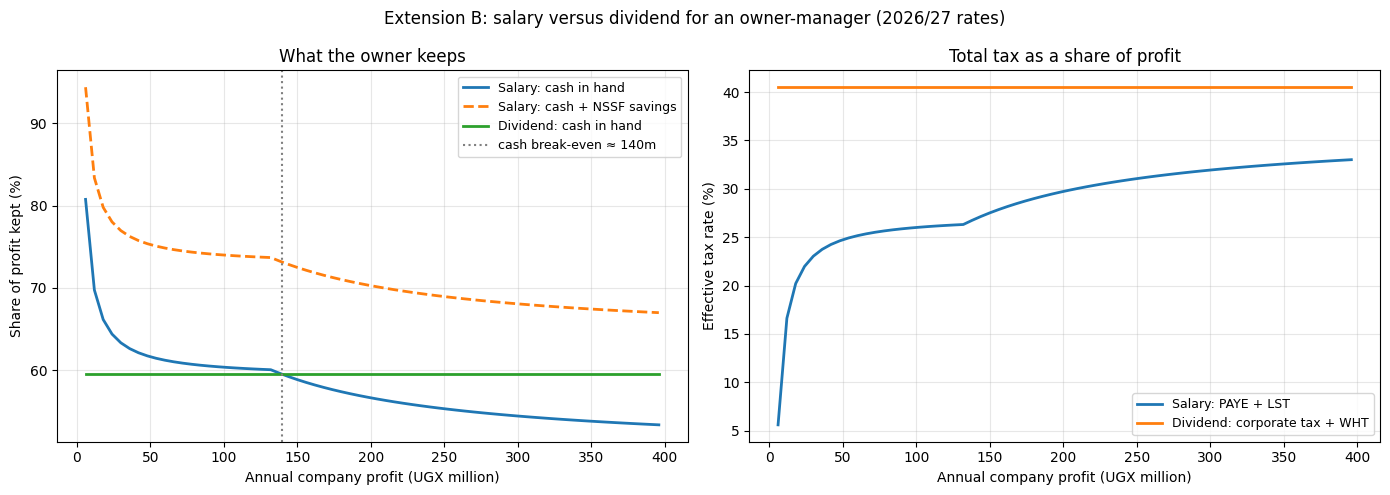

In [19]:
break_even = planner.break_even(salary, dividend, Money(5_000_000), Money(2_000_000_000))
print("Cash break-even annual profit:", break_even, f"(about {ugx(break_even) / 12 / 1.1:,.0f} gross salary a month)")

profits = [p * 1_000_000 for p in range(6, 401, 6)]
outs = [planner.compare(salary, dividend, Money(p)) for p in profits]
x = [p / 1e6 for p in profits]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(x, [100 * ugx(o.first.net_cash) / p for o, p in zip(outs, profits)], lw=2, label="Salary: cash in hand")
axes[0].plot(x, [100 * ugx(o.first.net_including_savings) / p for o, p in zip(outs, profits)], "--", lw=2, label="Salary: cash + NSSF savings")
axes[0].plot(x, [100 * ugx(o.second.net_cash) / p for o, p in zip(outs, profits)], lw=2, label="Dividend: cash in hand")
axes[0].axvline(ugx(break_even) / 1e6, color="grey", ls=":", label=f"cash break-even ≈ {ugx(break_even)/1e6:,.0f}m")
axes[0].set(title="What the owner keeps", xlabel="Annual company profit (UGX million)", ylabel="Share of profit kept (%)")
axes[1].plot(x, [100 * float(o.first.effective_tax_rate) for o in outs], lw=2, label="Salary: PAYE + LST")
axes[1].plot(x, [100 * float(o.second.effective_tax_rate) for o in outs], lw=2, label="Dividend: corporate tax + WHT")
axes[1].set(title="Total tax as a share of profit", xlabel="Annual company profit (UGX million)", ylabel="Effective tax rate (%)")
for ax in axes:
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
fig.suptitle("Extension B: salary versus dividend for an owner-manager (2026/27 rates)")
fig.tight_layout(); fig.savefig("figures/tax_planner.png", dpi=150); plt.show()

### Write-up

**Result.** The dividend route is taxed at a flat **40.5 %** of profit at every level (30 % corporate tax, then 15 % of the remaining 70 %). The salary route is progressive: almost nothing is taxed at low pay, and the marginal rate climbs to 30 % and then 40 % above 10,000,000 a month. So:

- **In tax terms, salary wins at every profit level tested**, because its top marginal rate (40 %) is still below the dividend's flat 40.5 %, and the lower bands are much cheaper.
- **In cash-in-hand terms, salary wins up to a profit of about UGX 140 million a year** (roughly 10.6 million gross a month). Above that, the dividend leaves more cash today, because the salary route diverts 15 % of gross into NSSF.
- If NSSF is counted as the owner's own money (the dashed line), salary is ahead throughout.

**How the design helped.** `TaxPlanner` contains no rates. `SalaryScenario` reuses `PayrollPipeline`, and `DividendScenario` reuses `CorporateIncomeTax` and `WithholdingTax`. A new scenario (e.g. half salary, half dividend) only needs a new `Scenario` subclass.

**Limits of the comparison.** It ignores the 10 % dividend rate for listed companies, the presumptive regime for small businesses, the timing of tax payments, access rules for NSSF savings, and anti-avoidance rules on unreasonably low salaries. It is a model for comparing structures, not tax advice.

## 10. Discussion questions

### Q1. Why is `float` unsafe for tax computation?

A `float` stores numbers in **binary**. Most decimal fractions (0.1, 0.15, 0.18, 0.30) have no exact binary form, so the computer stores the nearest value it can. Each stored value is wrong by a tiny amount, and the errors surface when you compare, add or round.

In [20]:
from decimal import ROUND_HALF_UP
import math

print("1) Basic arithmetic is not exact:")
print("   0.1 + 0.2 == 0.3  ->", 0.1 + 0.2 == 0.3, "  (0.1 + 0.2 =", repr(0.1 + 0.2) + ")")
print("   Decimal('0.1') + Decimal('0.2') == Decimal('0.3')  ->", Decimal("0.1") + Decimal("0.2") == Decimal("0.3"))

print("\n2) What 0.15 really is inside a float:")
print("  ", Decimal(0.15))

print("\n3) A concrete failing tax example: a payment of UGX 1,310,730 grossed up by 15% withholding tax")
amount = 1_310_730
as_float = amount * 1.15
float_result = math.floor(as_float + 0.5)                       # round half up, done with floats
exact = (Decimal(amount) * Decimal("1.15"))
decimal_result = int(exact.quantize(Decimal("1"), rounding=ROUND_HALF_UP))
print(f"   float  : {amount:,} x 1.15 = {as_float!r}  -> rounds to {float_result:,}")
print(f"   Decimal: {amount:,} x 1.15 = {exact}        -> rounds to {decimal_result:,}")
print(f"   Money  : {Money(amount) * Decimal('1.15')}")
assert float_result != decimal_result, "expected the float result to be wrong"
print(f"   The float answer is wrong by UGX {decimal_result - float_result}.")

print("\n4) Python's round() on floats adds a second surprise (banker's rounding):")
print("   round(184.5) =", round(184.5), "  but 18% VAT on 1,025 is 184.50, which half-up rounding makes 185 ->", Money(1025) * Decimal("0.18"))

print("\n5) Float sums depend on the order of addition, so two reports of the same data can disagree:")
vals = [0.1] * 10
print("   sum of ten 0.1s == 1.0 ->", sum(vals) == 1.0, "(", repr(sum(vals)), ")")

1) Basic arithmetic is not exact:
   0.1 + 0.2 == 0.3  -> False   (0.1 + 0.2 = 0.30000000000000004)
   Decimal('0.1') + Decimal('0.2') == Decimal('0.3')  -> True

2) What 0.15 really is inside a float:
   0.1499999999999999944488848768742172978818416595458984375

3) A concrete failing tax example: a payment of UGX 1,310,730 grossed up by 15% withholding tax
   float  : 1,310,730 x 1.15 = 1507339.4999999998  -> rounds to 1,507,339
   Decimal: 1,310,730 x 1.15 = 1507339.50        -> rounds to 1,507,340
   Money  : UGX 1,507,340
   The float answer is wrong by UGX 1.

4) Python's round() on floats adds a second surprise (banker's rounding):
   round(184.5) = 184   but 18% VAT on 1,025 is 184.50, which half-up rounding makes 185 -> UGX 185

5) Float sums depend on the order of addition, so two reports of the same data can disagree:
   sum of ten 0.1s == 1.0 -> False ( 0.9999999999999999 )


The exact answer in example 3 is 1,507,339.5, which rounds half up to 1,507,**340**. The float calculation produces 1,507,339.4999999998 and rounds to 1,507,**339**. One shilling looks trivial, but in a tax system it means: the engine's figure disagrees with URA's; totals across thousands of payslips do not reconcile; a comparison at a band edge (`income > 335000`) can go the wrong way; and the result can differ between machines or after reordering a sum. Tax figures must be **exactly reproducible**, so the engine uses `Decimal` created from integers or strings, never from floats, and `Money` refuses floats outright.

### Q2. Where is inheritance justified here, and where was it deliberately avoided?

**Used, because there is a genuine "is-a" relationship and shared interface:**
- `PAYE`, `NSSF`, `LocalServiceTax`, `VAT`, `CorporateIncomeTax`, `WithholdingTax` all inherit from the abstract `Tax`. Each **is a** tax and must offer `calculate(ctx) -> TaxResult`. This lets `PayrollPipeline`, `TaxPlanner` and the tests treat any tax uniformly (polymorphism).
- `SalaryScenario` and `DividendScenario` inherit from the abstract `Scenario`, so `TaxPlanner.compare` works with any pair of scenarios.
- `InvalidIncomeError`, `NoScheduleForDateError` and the others inherit from `TaxError`, so one `except TaxError` catches every engine error. Exception hierarchies are a classic good use of inheritance.

**Deliberately avoided:**
- **Resident and non-resident PAYE are not subclasses of `PAYE`.** They differ only in *data* (bands), not behaviour. The same is true of the 2012 and 2026 schedules. They are `ProgressiveSchedule` objects held in a registry. A subclass per rate table would mean a new class every time Parliament amends the bands.
- **`Money` does not inherit from `Decimal`.** It *has* a Decimal (composition). Inheriting would expose every Decimal operation, including ones that make no sense for money (multiplying two amounts, mixing with floats).
- **`PayrollPipeline` is not a `Tax`** and does not inherit from the taxes it runs. It *has* an LST, a PAYE and an NSSF object and can be handed different ones (e.g. LST disabled).
- **`TaxContext` has no subclasses** (no `EmploymentContext`, `VatContext`, …). One small immutable record keeps the `calculate(ctx)` signature identical for every tax. The price is a few optional fields, and each tax validates the ones it needs.
- **No `FlatRateTax` parent** for NSSF, corporate tax and withholding tax. Their only shared logic is one multiplication, and their bases and rules differ. A shared parent would couple unrelated taxes to save one line.

## 11. Limitations

- **Rates must be re-confirmed before submission.** The 2026 resident bands come from the brief and secondary summaries of the Income Tax (Amendment) Act, 2026; URA's rates page had not been updated when checked. The non-resident schedule is assumed unchanged.
- **Local Service Tax is simplified.** Sources differ on whether the bracket is set by gross or by take-home pay. This engine uses monthly gross, splits the annual amount into equal instalments, and makes all of this configurable.
- **Rounding.** Results are rounded half up to whole shillings once per calculation. URA's e-filing system may round at a different step; the rule is isolated in `Money._quantise` so it can be changed in one place.
- **Not modelled:** annual PAYE reconciliation, benefits in kind, exempt allowances, tax treaties, the VAT registration threshold, capital allowances and loss carry-forward, and the presumptive regime for small businesses.